<a href="https://colab.research.google.com/github/nowrin-12/rl-5g-scheduler/blob/main/phase_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q gymnasium stable-baselines3 numpy pandas matplotlib

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import DQN, PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_checker import check_env

os.makedirs("models", exist_ok=True)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [4]:
class BaseTowerSim:
    def __init__(self, num_users=10, bandwidth_mhz=20.0, seed=42):
        self.num_users = num_users
        self.bandwidth_mhz = bandwidth_mhz
        self.rng = np.random.default_rng(seed)
        self.reset_sim()

    def reset_sim(self, seed=None):
        if seed is not None:
            self.rng = np.random.default_rng(seed)
        self.distances = self.rng.uniform(50, 800, size=self.num_users)
        self.queues = self.rng.uniform(1.0, 10.0, size=self.num_users)
        self.delays = np.zeros(self.num_users, dtype=np.float32)
        self.avg_rates = np.ones(self.num_users, dtype=np.float32) * 5.0
        self.rr_idx = 0
        self.t = 0
        self.snr, self.rates = self._compute_channel()
        return self.snr, self.rates

    def _compute_channel(self):
        path_loss_db = 28.0 + 22.0 * np.log10(np.maximum(self.distances, 10.0))
        fading = self.rng.exponential(scale=1.0, size=self.num_users)
        snr_linear = (10.0 ** (-path_loss_db / 10.0)) * (10.0 ** 12) * fading
        snr_linear = np.clip(snr_linear, 0.05, 100.0)
        rates_mbps = self.bandwidth_mhz * np.log2(1.0 + snr_linear) * 0.1
        return snr_linear.astype(np.float32), rates_mbps.astype(np.float32)

    def step_traffic(self):
        arrivals = self.rng.exponential(scale=1.5, size=self.num_users)
        self.queues += arrivals
        self.delays = np.where(self.queues > 1e-3, self.delays + 1.0, 0.0)
        move = self.rng.normal(0, 15.0, size=self.num_users)
        self.distances = np.clip(self.distances + move, 30.0, 1000.0)
        self.snr, self.rates = self._compute_channel()
        self.t += 1

    def serve_user(self, user_idx):
        sent = min(self.queues[user_idx], self.rates[user_idx])
        self.queues[user_idx] -= sent
        if self.queues[user_idx] <= 1e-3:
            self.queues[user_idx] = 0.0
            self.delays[user_idx] = 0.0

        alpha = 0.1
        for i in range(self.num_users):
            inst = sent if i == user_idx else 0.0
            self.avg_rates[i] = (1 - alpha) * self.avg_rates[i] + alpha * inst

        denom = self.num_users * np.sum(self.avg_rates ** 2)
        fairness = (np.sum(self.avg_rates) ** 2) / denom if denom > 0 else 1.0
        return float(sent), float(fairness)

    def pick_baseline_action(self, policy="pf"):
        if policy == "rr":
            action = self.rr_idx % self.num_users
            self.rr_idx += 1
            return action
        elif policy == "max_ci":
            return int(np.argmax(self.snr))
        elif policy == "pf":
            pf_metric = self.rates / np.maximum(self.avg_rates, 1e-3)
            return int(np.argmax(pf_metric))
        raise ValueError(f"Unknown policy: {policy}")


class TowerSchedulerEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, num_users=10, max_steps=200, seed=42):
        super().__init__()
        self.num_users = num_users
        self.max_steps = max_steps
        self.sim = BaseTowerSim(num_users=num_users, seed=seed)

        self.action_space = spaces.Discrete(num_users)
        self.observation_space = spaces.Box(
            low=0.0, high=1.0, shape=(num_users * 4,), dtype=np.float32
        )
        self.current_step = 0

    def _get_obs(self):
        norm_snr = np.clip(self.sim.snr / 100.0, 0.0, 1.0)
        norm_q = np.clip(self.sim.queues / 20.0, 0.0, 1.0)
        norm_d = np.clip(self.sim.delays / 100.0, 0.0, 1.0)
        norm_r = np.clip(self.sim.avg_rates / 20.0, 0.0, 1.0)
        return np.concatenate([norm_snr, norm_q, norm_d, norm_r]).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        self.sim.reset_sim(seed=seed)
        return self._get_obs(), {}

    def step(self, action):
        self.current_step += 1
        sent, fairness = self.sim.serve_user(int(action))
        mean_delay = float(np.mean(self.sim.delays))

        reward = (0.5 * sent) + (2.0 * fairness) - (0.05 * mean_delay)

        self.sim.step_traffic()
        terminated = False
        truncated = self.current_step >= self.max_steps
        info = {"throughput": sent, "fairness": fairness, "mean_delay": mean_delay}
        return self._get_obs(), float(reward), terminated, truncated, info


env_check = TowerSchedulerEnv(num_users=10, max_steps=200, seed=42)
check_env(env_check, warn=True)

In [5]:
class RewardLoggerCallback(BaseCallback):
    def __init__(self, check_freq=1000, verbose=0):
        super().__init__(verbose)
        self.check_freq = check_freq
        self.timesteps = []
        self.mean_rewards = []
        self.episode_rewards = []

    def _on_step(self) -> bool:
        for info in self.locals.get("infos", []):
            if "episode" in info:
                self.episode_rewards.append(info["episode"]["r"])

        if self.n_calls % self.check_freq == 0 and len(self.episode_rewards) > 0:
            self.timesteps.append(self.num_timesteps)
            self.mean_rewards.append(float(np.mean(self.episode_rewards[-20:])))
        return True

In [6]:
dqn_env = Monitor(TowerSchedulerEnv(num_users=10, max_steps=200, seed=101))
dqn_eval_env = Monitor(TowerSchedulerEnv(num_users=10, max_steps=200, seed=202))
dqn_cb = RewardLoggerCallback(check_freq=1000)

dqn_model = DQN(
    "MlpPolicy",
    dqn_env,
    learning_rate=1e-3,
    buffer_size=20000,
    learning_starts=1000,
    batch_size=64,
    exploration_fraction=0.3,
    exploration_final_eps=0.05,
    verbose=0,
    seed=42,
)

dqn_model.learn(total_timesteps=40000, callback=dqn_cb)
dqn_model.save("models/dqn_tower_10u")

dqn_mean, dqn_std = evaluate_policy(dqn_model, dqn_eval_env, n_eval_episodes=20)
print(f"DQN Eval Reward (10 users): {dqn_mean:.2f} +/- {dqn_std:.2f}")

DQN Eval Reward (10 users): 736.49 +/- 40.40


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [7]:
ppo_env = Monitor(TowerSchedulerEnv(num_users=10, max_steps=200, seed=101))
ppo_eval_env = Monitor(TowerSchedulerEnv(num_users=10, max_steps=200, seed=202))
ppo_cb = RewardLoggerCallback(check_freq=1000)

ppo_model = PPO(
    "MlpPolicy",
    ppo_env,
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    verbose=0,
    seed=42,
)

ppo_model.learn(total_timesteps=40000, callback=ppo_cb)
ppo_model.save("models/ppo_tower_10u")

ppo_mean, ppo_std = evaluate_policy(ppo_model, ppo_eval_env, n_eval_episodes=20)
print(f"PPO Eval Reward (10 users): {ppo_mean:.2f} +/- {ppo_std:.2f}")

PPO Eval Reward (10 users): -347.14 +/- 28.32


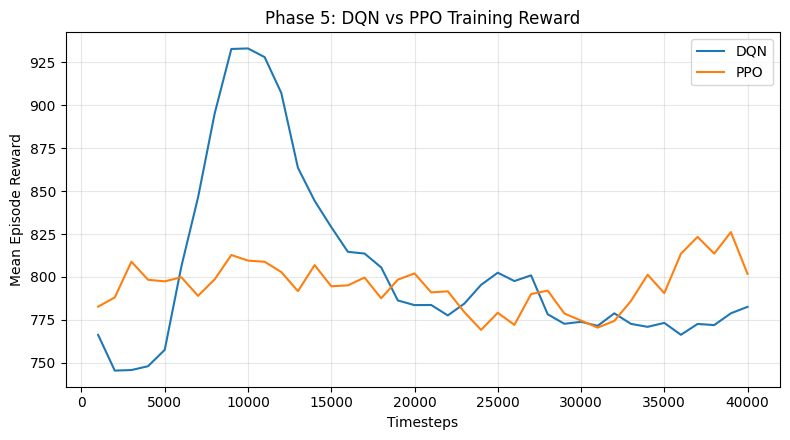

In [8]:
plt.figure(figsize=(8, 4.5))
if len(dqn_cb.timesteps) > 0:
    plt.plot(dqn_cb.timesteps, dqn_cb.mean_rewards, label="DQN")
if len(ppo_cb.timesteps) > 0:
    plt.plot(ppo_cb.timesteps, ppo_cb.mean_rewards, label="PPO")

plt.title("Phase 5: DQN vs PPO Training Reward")
plt.xlabel("Timesteps")
plt.ylabel("Mean Episode Reward")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()